# We are analyzing the Titanic passenger dataset to see if there is any association between survival and categorical variables: gender and passenger class. Specifically, we will use the Chi-square test of independence.

In [1]:
import pandas as pd
from scipy.stats import chi2_contingency

def chi_square_test(data, col1, col2, alpha=0.05):
    contingency_table = pd.crosstab(data[col1], data[col2])
    print("\nContingency Table:")
    print(contingency_table)

    chi2, p, dof, expected = chi2_contingency(contingency_table)

    print(f"\nChi-Square Statistic = {chi2:.4f}")
    print(f"Degrees of Freedom   = {dof}")
    print(f"P-Value              = {p:.4f}")

    if p < alpha:
        print(f"Decision: Reject H0 (There is a significant relationship between {col1} and {col2})")
    else:
        print(f"Decision: Fail to reject H0 (No significant relationship between {col1} and {col2})")

df = pd.read_csv("Titanic-Dataset.csv")
chi_square_test(df, "Survived", "Sex")
chi_square_test(df, "Survived", "Pclass")


Contingency Table:
Sex       female  male
Survived              
0             81   468
1            233   109

Chi-Square Statistic = 260.7170
Degrees of Freedom   = 1
P-Value              = 0.0000
Decision: Reject H0 (There is a significant relationship between Survived and Sex)

Contingency Table:
Pclass      1   2    3
Survived              
0          80  97  372
1         136  87  119

Chi-Square Statistic = 102.8890
Degrees of Freedom   = 2
P-Value              = 0.0000
Decision: Reject H0 (There is a significant relationship between Survived and Pclass)


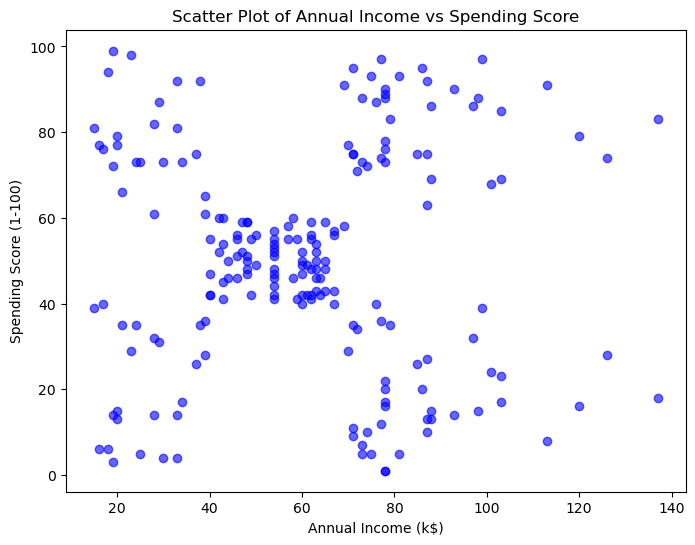

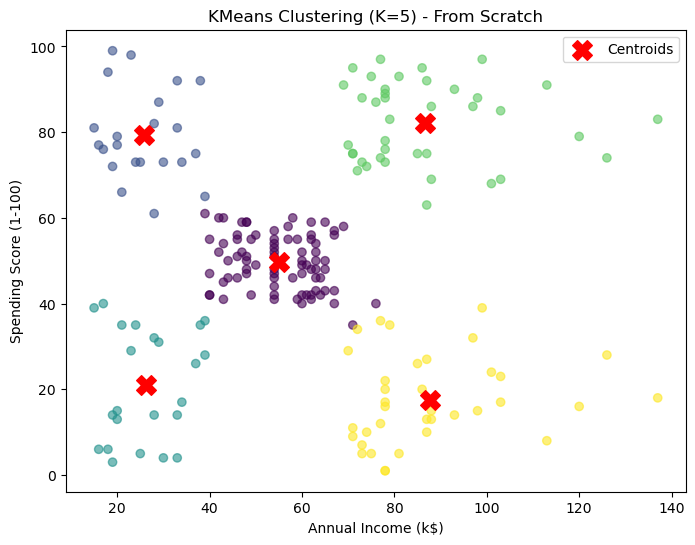

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "Mall_Customers.csv"
df = pd.read_csv(file_path)

plt.figure(figsize=(8,6))
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"], 
            c="blue", alpha=0.6)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Scatter Plot of Annual Income vs Spending Score")
plt.show()

X = df[["Annual Income (k$)", "Spending Score (1-100)"]].values

K = 5
np.random.seed(42)

centroids = X[np.random.choice(X.shape[0], K, replace=False)]
def assign_clusters(X, centroids):
    distances = np.linalg.norm(X[:, None] - centroids, axis=2)
    return np.argmin(distances, axis=1)

def update_centroids(X, labels, K):
    return np.array([X[labels == k].mean(axis=0) for k in range(K)])

for _ in range(100):
    labels = assign_clusters(X, centroids)
    new_centroids = update_centroids(X, labels, K)
    if np.allclose(centroids, new_centroids):
        break
    centroids = new_centroids

plt.figure(figsize=(8,6))
plt.scatter(X[:,0], X[:,1], c=labels, cmap="viridis", alpha=0.6)
plt.scatter(centroids[:,0], centroids[:,1], 
            c="red", marker="X", s=200, label="Centroids")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("KMeans Clustering (K=5) - From Scratch")
plt.legend()
plt.show()
